In [ ]:
%pip install gwpy gwosc scipy # to get noise data
%pip install pycbc # to generate waveforms

In [1]:
from gwpy.timeseries import TimeSeries
from gwosc.datasets import event_gps

# finding quiet noise
from gwosc.datasets import find_datasets, run_segment

# get only 01, set 01 boundaries
start_o1, end_o1 = run_segment("O1")
print(start_o1, end_o1)

# all confirmed 01 event names
events_o1 = find_datasets(type="event", segment=(start_o1, end_o1))
print(events_o1)

/Users/roxydhyana/miniconda3/lib/python3.13/site-packages/gwpy/time/_ligotimegps.py:42: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS


1126051217 1137254417
['151008-v1', '151012.2-v1', '151116-v1', 'GW150914-v1', 'GW150914-v2', 'GW150914-v3', 'GW150914-v4', 'GW151012-v1', 'GW151012-v2', 'GW151012-v3', 'GW151012-v4', 'GW151226-v1', 'GW151226-v2', 'GW151226-v3']


In [2]:
# event names + event times
event_times = {name: event_gps(name) for name in events_o1}
print(event_times)

{'151008-v1': 1128348574.5, '151012.2-v1': 1128666662.2, '151116-v1': 1131748925.7, 'GW150914-v1': 1126259462.4, 'GW150914-v2': 1126259462.4, 'GW150914-v3': 1126259462.4, 'GW150914-v4': 1126259462.4, 'GW151012-v1': 1128678900.4, 'GW151012-v2': 1128678900.4, 'GW151012-v3': 1128678900.4, 'GW151012-v4': 1128678900.4, 'GW151226-v1': 1135136350.6, 'GW151226-v2': 1135136350.6, 'GW151226-v3': 1135136350.6}


In [3]:
# making noise-only segments

# segment 1
noise1_start, noise1_end = 1126100000, 1126100600
noise1_data = TimeSeries.fetch_open_data("H1", noise1_start, noise1_end, cache=True)
noise1_array = noise1_data.value # gwpy TimeSeries -> numpy array

#segment 2
noise2_start, noise2_end = 1127000000, 1127000600
noise2_data = TimeSeries.fetch_open_data("H1", noise2_start, noise2_end, cache=True)
noise2_array = noise2_data.value # gwpy TimeSeries -> numpy array

#segment 3
noise3_start, noise3_end = 1129000000, 1129000600
noise3_data = TimeSeries.fetch_open_data("H1", noise3_start, noise3_end, cache=True)
noise3_array = noise3_data.value # gwpy TimeSeries -> numpy array

# segment 4
noise4_start, noise4_end = 1131000000, 1131000600
noise4_data = TimeSeries.fetch_open_data("H1", noise4_start, noise4_end, cache=True)
noise4_array = noise4_data.value # gwpy TimeSeries -> numpy array

# segment 5
noise5_start, noise5_end = 1133000000, 1133000600
noise5_data = TimeSeries.fetch_open_data("H1", noise5_start, noise5_end, cache=True)
noise5_array = noise5_data.value # gwpy TimeSeries -> numpy array

# segment 6
noise6_start, noise6_end = 1134000000, 1134000600
noise6_data = TimeSeries.fetch_open_data("H1", noise6_start, noise6_end, cache=True)
noise6_array = noise6_data.value # gwpy TimeSeries -> numpy array

for i, d in enumerate([noise1_data, noise2_data, noise3_data, noise4_data, noise5_data, noise6_data], 1):
    print(i, d.duration)

# 3,600 total seconds of noise
noise_list = ([noise1_data, noise2_data, noise3_data, noise4_data, noise5_data, noise6_data])

1 600.0 s
2 600.0 s
3 600.0 s
4 600.0 s
5 600.0 s
6 600.0 s


In [9]:
# making 2,400 1.5 segment clips from the 3,600 seconds of total noise

def make_noise_clips(noise_list, clip_length=1.5, sample_rate=4096):
    samples_per_clip = int(clip_length * sample_rate)
    clips = []
    for segment in noise_list: # looping through all 6 segments
        data_arr = segment.value # making array of waveform data values
        n_clips = len(data_arr) // samples_per_clip
        for i in range(n_clips): # loops through each segment
            start = i * samples_per_clip # sets start time of each new segment clip
            clips.append(data_arr[start:start + samples_per_clip])
    return clips

noise_clips = make_noise_clips(noise_list)
print(len(noise_clips))

2400


In [10]:
# creating waveforms to inject into noise clips

import numpy as np
from pycbc.waveform import get_td_waveform

def crop_event_merger(hp, before=1.0, after=0.5):
    start_crop = -before - hp.start_time # crops for 1.0 secs from start
    end_crop = hp.end_time - after          # crops for 0.5 secs from end
    return hp.crop(start_crop, end_crop)

def generate_waveforms(n_waveforms, mass_min=5, mass_max=75, f_lower=30):
    waveforms = []
    for _ in range(n_waveforms):
        mass1 = np.random.uniform(mass_min, mass_max)
        mass2 = np.random.uniform(mass_min, mass_max)
        
        hp, hc = get_td_waveform(
            approximant="IMRPhenomD",
            mass1=mass1,
            mass2=mass2,
            delta_t=1.0/4096,
            f_lower=f_lower
        )
        
        hp_cropped = crop_event_merger(hp, before=1.0, after=0.5)
        waveforms.append(hp_cropped)
    
    return waveforms

waveforms = generate_waveforms(2400)
print(len(waveforms))

2400


In [7]:
# control SNR would be the vital step here

In [12]:
# just for fun injecting the signal intot he noise

injected_clips = [noise + signal for noise, signal in zip(noise_clips, waveforms)]
print(len(injected_clips))

2400


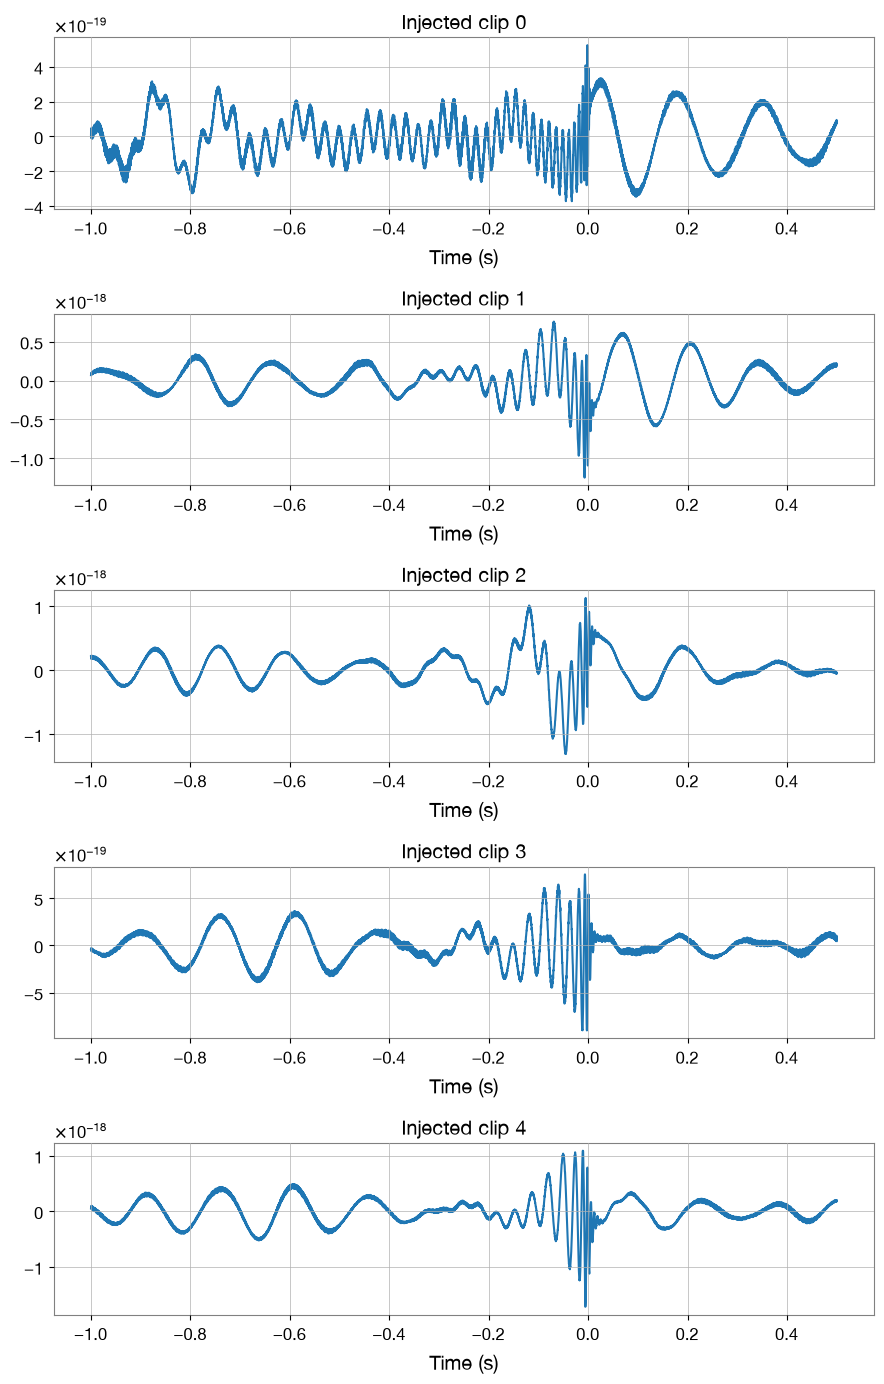

In [19]:
import matplotlib.pyplot as plt

time_axis = np.linspace(-1.0, 0.5, len(injected_clips[0]))

fig, axes = plt.subplots(5, 1, figsize=(9, 14))
for i in range(5):
    axes[i].plot(time_axis, injected_clips[i])
    axes[i].set_title(f"Injected clip {i}")
    axes[i].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()